# 1. Visualising NCA Attractors -- Blue/Green Gecko (Macroscopic)
## Convolutional autoencoder / tracking attractor formation during training
### James Stovold
### April 2026


Code to support ALIFE 2026 paper:
 > Stovold, Kvalsund, Ludwig, Sharma, Mordvintsev "Visualising the Attractor Landscape of Neural Cellular Automata"

Based on the Colab notebook developed by Mordvintsev et al. for the ["Growing Neural Cellular Automata"](http://distill.pub/2020/growing-ca) article. and J. Stovold's notebook for the ["Neural Cellular Automata can Respond to Signals"](https://github.com/jstovold/ALIFE2023/blob/master/ExternalSignals.ipynb) article at ALIFE 2023.

Code and materials are restricted for any and all use prior to publication; post-publication the code and associated materials are available under the Apache 2.0 license


In [3]:
import tensorflow as tf
gpus = tf.config.list_physical_devices('GPU')
if gpus:
  try:
    # Currently, memory growth needs to be the same across GPUs
    for gpu in gpus:
      tf.config.experimental.set_memory_growth(gpu, True)
    logical_gpus = tf.config.list_logical_devices('GPU')
    print(len(gpus), "Physical GPUs,", len(logical_gpus), "Logical GPUs")
  except RuntimeError as e:
    # Memory growth must be set before GPUs have been initialized
    print(e)


2 Physical GPUs, 2 Logical GPUs


In [4]:
root_dir = './jamess/ALICE_Paper/1b_bluegreengecko/'
!mkdir -p {root_dir}

In [5]:

#@title Imports and Notebook Utilities


import os
import io
import PIL.Image, PIL.ImageDraw
import base64
import zipfile
import json
import requests
import numpy as np
import matplotlib.pylab as pl
import glob
import random
import datetime

from scipy.ndimage.interpolation import rotate as scipy_rotate


import tensorflow as tf

from IPython.display import Image, HTML, clear_output
import tqdm

import os
os.environ['FFMPEG_BINARY'] = 'ffmpeg'
import moviepy as mvp
from moviepy.video.io.ffmpeg_writer import FFMPEG_VideoWriter
clear_output()

def np2pil(a):
  if a.dtype in [np.float32, np.float64]:
    a = np.uint8(np.clip(a, 0, 1)*255)
  return PIL.Image.fromarray(a)

def imwrite(f, a, fmt=None):
  a = np.asarray(a)
  if isinstance(f, str):
    fmt = f.rsplit('.', 1)[-1].lower()
    if fmt == 'jpg':
      fmt = 'jpeg'
    f = open(f, 'wb')
  np2pil(a).save(f, fmt, quality=95)

def imencode(a, fmt='jpeg'):
  a = np.asarray(a)
  if len(a.shape) == 3 and a.shape[-1] == 4:
    fmt = 'png'
  f = io.BytesIO()
  imwrite(f, a, fmt)
  return f.getvalue()

def im2url(a, fmt='jpeg'):
  encoded = imencode(a, fmt)
  base64_byte_string = base64.b64encode(encoded).decode('ascii')
  return 'data:image/' + fmt.upper() + ';base64,' + base64_byte_string

def imshow(a, fmt='jpeg'):
  display(Image(data=imencode(a, fmt)))

def tile2d(a, w=None):
  a = np.asarray(a)
  if w is None:
    w = int(np.ceil(np.sqrt(len(a))))
  th, tw = a.shape[1:3]
  pad = (w-len(a))%w
  a = np.pad(a, [(0, pad)]+[(0, 0)]*(a.ndim-1), 'constant')
  h = len(a)//w
  a = a.reshape([h, w]+list(a.shape[1:]))
  a = np.rollaxis(a, 2, 1).reshape([th*h, tw*w]+list(a.shape[4:]))
  return a

def zoom(img, scale=4):
  img = np.repeat(img, scale, 0)
  img = np.repeat(img, scale, 1)
  return img

def rotate(img, angle=90):
  img = scipy_rotate(img, angle=angle)
  return img

class VideoWriter:
  def __init__(self, filename, fps=30.0, **kw):
    self.writer = None
    self.params = dict(filename=filename, fps=fps, **kw)

  def add(self, img):
    img = np.asarray(img)
    if self.writer is None:
      h, w = img.shape[:2]
      self.writer = FFMPEG_VideoWriter(size=(w, h), **self.params)
    if img.dtype in [np.float32, np.float64]:
      img = np.uint8(img.clip(0, 1)*255)
    if len(img.shape) == 2:
      img = np.repeat(img[..., None], 3, -1)
    self.writer.write_frame(img)

  def close(self):
    if self.writer:
      self.writer.close()

  def __enter__(self):
    return self

  def __exit__(self, *kw):
    self.close()



In [6]:
#@title Cellular Automata Parameters

# no "genome" for external signals:
PARAM_N  = 0                        # Number of genes in the genome
OTHER_N  = 12                       # Number of "empty" spaces in the genome for the CA to communicate between cells
ENV_N    = 1                        # Number of environment channels (not editable by cells)

# Total number of CA state channels (+ 4 for RGBA):
CHANNEL_N = 4 + PARAM_N + OTHER_N + ENV_N

TARGET_PADDING = 15                 # Number of pixels used to pad the target image border
TARGET_SIZE = 30
TARGET_PADDED_SIZE = TARGET_SIZE + TARGET_PADDING * 2

BATCH_SIZE = 12
POOL_SIZE = 1024
CELL_FIRE_RATE = 0.5

EXPERIMENT_TYPE = "Regenerating" #param ["Growing", "Persistent", "Regenerating"]
EXPERIMENT_MAP = {"Growing":0, "Persistent":1, "Regenerating":2}
EXPERIMENT_N = EXPERIMENT_MAP[EXPERIMENT_TYPE]

USE_PATTERN_POOL = [0, 1, 1][EXPERIMENT_N]
DAMAGE_N = [0, 0, 3][EXPERIMENT_N]  # Number of patterns to damage in a batch

BEHAVIOUR_SWITCH=2000               # at what point do we change the way we present the target images to the network?

fix_seed = True                     # for reproducibility
loading_from_file = False


In [8]:
#@title CA Model and Utilities

from tensorflow.keras.layers import Conv2D


def load_image(url, max_size=TARGET_SIZE, zoom=1):
  r = requests.get(url)
  img = PIL.Image.open(io.BytesIO(r.content))
  img.thumbnail((max_size*zoom, max_size*zoom), PIL.Image.LANCZOS)
  img = np.float32(img)/255.0
  img[...,:3] *= img[..., 3:]
  return img


def load_heart(colour="green", zoom=1):
  url = "https://github.com/jstovold/ALIFE2023/blob/master/hearts/emoji_u2764_" + colour + ".png?raw=true"
  return load_image(url, zoom=zoom)


def load_gecko(colour='green',zoom=1):
  url = f"https://github.com/jstovold/ALIFE2023/blob/master/geckos/emoji_u1f98e_{colour}.png?raw=true"
  return load_image(url, zoom=zoom)


def to_rgba(x):
  return x[..., :4]

def to_alpha(x):
  return tf.clip_by_value(x[..., 3:4], 0.0, 1.0)

def to_rgb(x):
  # assume rgb premultiplied by alpha
  rgb, a = x[..., :3], to_alpha(x)
  return 1.0-a+rgb


def get_channels(x, ch=[5,6,7]):
  rgb, a = x[..., ch], to_alpha(x)
  return 1.0-a+rgb

def get_living_mask(x, threshold = 0.1):
  alpha = x[:, :, :, 3:4]
  return tf.nn.max_pool2d(alpha, 3, [1, 1, 1, 1], 'SAME') > threshold

def get_living(x):
  alpha = x[0, :, :, 3:4]
  return tf.nn.max_pool2d(alpha, 3, [1, 1, 1, 1], 'SAME') > 0.1


def make_seed(size, n=1):
  x = np.zeros([n, size, size, CHANNEL_N], np.float32)
  x[:, size//2, size//2, 3:] = 1.0
  return x


@tf.function
def get_stim(jitter=False):
  size = TARGET_PADDED_SIZE
  stim_x = (size // 2) - (TARGET_SIZE // 10)
  stim_y = (size // 2) - (TARGET_SIZE // 10)

  if jitter:
    rand = tf.random.uniform(shape=(), minval=-1, maxval=1, dtype=tf.int32)
    stim_x = stim_x + rand
    stim_y = stim_y + rand

  return (stim_x, stim_y)

class CAModel(tf.keras.Model):

  def __init__(self, channel_n=CHANNEL_N, fire_rate=CELL_FIRE_RATE):
    super().__init__()
    self.channel_n = channel_n
    self.fire_rate = fire_rate

    self.dmodel = tf.keras.Sequential([
          Conv2D(128, 1, activation=tf.nn.relu, name='layer1'),
          Conv2D(self.channel_n - ENV_N, 1, activation=None,             # no update for ENV_N state
              kernel_initializer=tf.zeros_initializer, name='layer2'),
    ])

    self(tf.zeros([1, 3, 3, channel_n]))  # dummy call to build the model

  @tf.function
  def perceive(self, x, angle=0.0):
    identify = np.float32([0, 1, 0])
    identify = np.outer(identify, identify)
    dx = np.outer([1, 2, 1], [-1, 0, 1]) / 8.0  # Sobel filter
    dy = dx.T
    c, s = tf.cos(angle), tf.sin(angle)
    kernel = tf.stack([identify, c*dx-s*dy, s*dx+c*dy], -1)[:, :, None, :]
    kernel = tf.repeat(kernel, self.channel_n, 2)
    y = tf.nn.depthwise_conv2d(x, kernel, [1, 1, 1, 1], 'SAME')
    return y

  @tf.function
  def call(self, x, fire_rate=None, angle=0.0, step_size=1.0):
    pre_life_mask = get_living_mask(x)
    y = self.perceive(x, angle)


    z = self.dmodel(y)
    dx = z*step_size


    if fire_rate is None:
      fire_rate = self.fire_rate
    update_mask = tf.random.uniform(tf.shape(x[:, :, :, :1])) <= fire_rate
    x = x[...,:-ENV_N] + dx * tf.cast(update_mask, tf.float32)
    x = tf.pad(x, tf.constant([[0,0],[0,0],[0,0], [0,ENV_N]]), constant_values=0) # add the environment vars back into the state vector (set to 0)

    post_life_mask = get_living_mask(x)
    life_mask = pre_life_mask & post_life_mask
    return x * tf.cast(life_mask, tf.float32)


CAModel().dmodel.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ layer1 (Conv2D)                 │ (1, 3, 3, 128)         │         6,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer2 (Conv2D)                 │ (1, 3, 3, 16)          │         2,064 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,720 (34.06 KB)

 Trainable params: 8,720 (34.06 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#@title Train Utilities (SamplePool, Model Export, Damage)
from google.protobuf.json_format import MessageToDict
from tensorflow.python.framework import convert_to_constants

class SamplePool:
  def __init__(self, *, _parent=None, _parent_idx=None, **slots):
    self._parent = _parent
    self._parent_idx = _parent_idx
    self._slot_names = slots.keys()
    self._size = None
    for k, v in slots.items():
      if self._size is None:
        self._size = len(v)
      assert self._size == len(v)
      setattr(self, k, np.asarray(v))

  def sample(self, n):
    idx = np.random.choice(self._size, n, False)
    batch = {k: getattr(self, k)[idx] for k in self._slot_names}
    batch = SamplePool(**batch, _parent=self, _parent_idx=idx)
    return batch

  def commit(self):
    for k in self._slot_names:
      getattr(self._parent, k)[self._parent_idx] = getattr(self, k)


def export_model(ca, base_fn):
  ca.save_weights(base_fn)

  cf = ca.call.get_concrete_function(
      x=tf.TensorSpec([None, None, None, CHANNEL_N]),
      fire_rate=tf.constant(0.5),
      angle=tf.constant(0.0),
      step_size=tf.constant(1.0))
  cf = convert_to_constants.convert_variables_to_constants_v2(cf)
  graph_def = cf.graph.as_graph_def()
  graph_json = MessageToDict(graph_def)
  graph_json['versions'] = dict(producer='1.14', minConsumer='1.14')
  model_json = {
      'format': 'graph-model',
      'modelTopology': graph_json,
      'weightsManifest': [],
  }
  with open(base_fn+'.json', 'w') as f:
    json.dump(model_json, f)

def generate_pool_figures(pool, step_i):
  tiled_pool = tile2d(to_rgb(pool.x[:49]))
  fade = np.linspace(1.0, 0.0, 72)
  ones = np.ones(72)
  tiled_pool[:, :72]  += (-tiled_pool[:,  :72] + ones[None, :, None]) * fade[None, :,    None]
  tiled_pool[:, -72:] += (-tiled_pool[:, -72:] + ones[None, :, None]) * fade[None, ::-1, None]
  tiled_pool[:72, :]  += (-tiled_pool[:72,  :] + ones[:, None, None]) * fade[:,    None, None]
  tiled_pool[-72:, :] += (-tiled_pool[-72:, :] + ones[:, None, None]) * fade[::-1, None, None]
  imwrite(f'{root_dir}/train_log/{step_i:04d}_pool.jpg', tiled_pool)

def visualize_batch(x0, x, y0, step_i):
  vis0 = np.hstack(to_rgb(x0).numpy())
  vis1 = np.hstack(to_rgb(x).numpy())
  vis2 = np.hstack(to_rgb(y0).numpy())
  vis = np.vstack([vis0, vis1, vis2])
  imwrite(f'{root_dir}/train_log/batches_{step_i:04d}.jpg', vis)
  print('batch (before/after):')
  imshow(zoom(vis,2))

def plot_loss(loss_log):
  pl.figure(figsize=(10, 4))
  pl.title('Loss history (log10)')
  pl.plot(np.log10(loss_log), '.', alpha=0.1)
  pl.show()


@tf.function
def make_circle_masks(n, h, w):
  x = tf.linspace(-1.0, 1.0, w)[None, None, :]
  y = tf.linspace(-1.0, 1.0, h)[None, :, None]
  center = tf.random.uniform([2, n, 1, 1], -0.5, 0.5)
  r = tf.random.uniform([n, 1, 1], 0.1, 0.4)
  x, y = (x-center[0])/r, (y-center[1])/r
  mask = tf.cast(x*x+y*y < 1.0, tf.float32)
  return mask


(60, 60, 4)


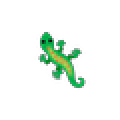

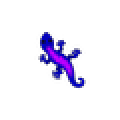

In [ ]:
#@title Pull the images from github according to genome { vertical-output: true }

target_img_1 = load_gecko('green')
target_img_2 = load_gecko('blue')

h, w = target_img_1.shape[:2]

p = (TARGET_PADDED_SIZE - h) // 2
padded_img_1 = tf.pad(target_img_1, [[p, p], [p,p], [0,0]])
padded_img_2 = tf.pad(target_img_2, [[p, p], [p,p], [0,0]])

print(padded_img_1.shape)

imshow(zoom(to_rgba(padded_img_1),2),fmt='png')
imshow(zoom(to_rgba(padded_img_2),2),fmt='png')



In [ ]:
#@title Initialize Training { vertical-output: true}


h, w = padded_img_1.shape[:2]
print(h,w)
seed = np.zeros([h, w, CHANNEL_N], np.float32)
seed[h//2, w//2, 3:]  = 1.0
# seed[h//2, w//2, -ENV_N:] = 0.0

def loss_f(x, y):
  return tf.reduce_mean(tf.square(to_rgba(x)-to_rgba(y)), [-2, -3, -1])

ca = CAModel()

loss_log = []

lr = 2e-3
lr_sched = tf.keras.optimizers.schedules.PiecewiseConstantDecay(
    [3000, 5000, 6000, 10000], [lr, lr*0.5, lr * 0.1, lr * 0.05, lr*0.01])
trainer = tf.keras.optimizers.Adam(lr_sched)


loss0 = loss_f(seed[None,...], padded_img_1[None,...]).numpy()

pool = SamplePool(x=np.repeat(seed[None, ...], POOL_SIZE, 0),
                  y=np.repeat(padded_img_1[None, ...], POOL_SIZE, 0),
                  z=np.repeat(0, POOL_SIZE,0))
if not loading_from_file:
    !mkdir -p {root_dir}/train_log && rm -f {root_dir}/train_log/*

60 60


batch (before/after):


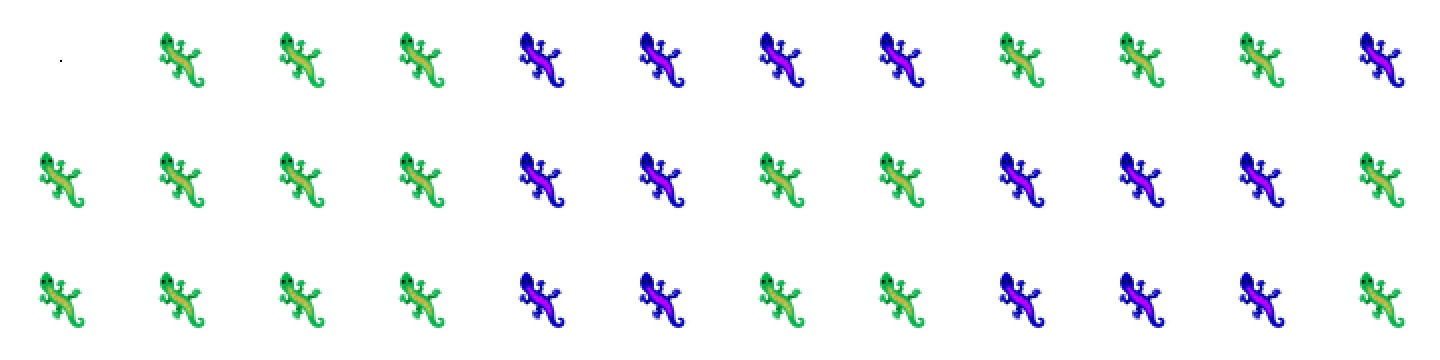

[ 0  0  2 14  9  1  2  6 17  1  1  6]


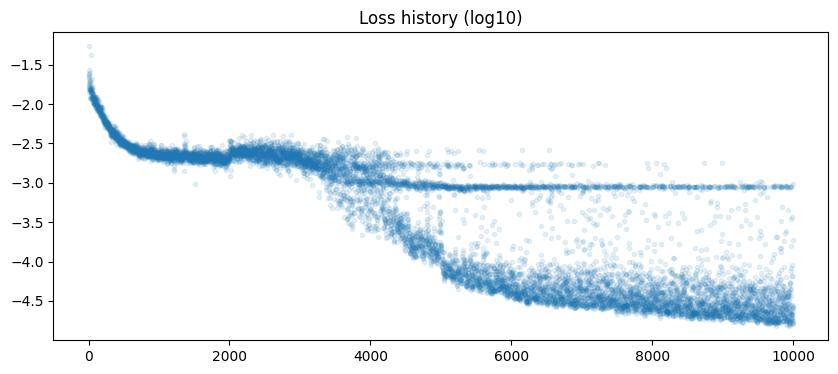

I0000 00:00:1772381803.734591 1086946 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1772381803.734807 1086946 single_machine.cc:376] Starting new session
I0000 00:00:1772381803.744703 1086946 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 78928 MB memory:  -> device: 0, name: NVIDIA A100 80GB PCIe, pci bus id: 0002:00:00.0, compute capability: 8.0


 step: 10001, log10(loss): -4.790
 0:29:20.298332


In [ ]:
#@title Training Loop {vertical-output: true}

@tf.function
def train_step(x, y):
  iter_n = tf.random.uniform([], 64, 96, tf.int32)
  with tf.GradientTape() as g:
    for i in tf.range(iter_n):
      x = ca(x)
    loss = tf.reduce_mean(loss_f(x, y))
  grads = g.gradient(loss, ca.weights)
  grads = [g/(tf.norm(g)+1e-8) for g in grads]
  trainer.apply_gradients(zip(grads, ca.weights))
  return x, loss


@tf.function
def make_seed_env():
  h, w = (TARGET_PADDED_SIZE, TARGET_PADDED_SIZE)
  seed = np.zeros([h, w, CHANNEL_N], np.float32)
  seed[h//2, w//2, 3:] = 1.0
  seed[h//2,w//2,-ENV_N:] = 0
  return seed


@tf.function
def get_target(numSignals):
  if numSignals % 2 == 0:
    target_img_scale = target_img_1
  else:
    # target_img_scale = target_img_1
    target_img_scale = target_img_2

  img_w = target_img_scale.shape[:1][0]
  p = (TARGET_PADDED_SIZE - img_w) // 2
  pad_target_temp = tf.pad(to_rgba(target_img_scale), [[p, p], [p,p], [0,0]])
  return(pad_target_temp)


if fix_seed:
  tf.random.set_seed(1)

tic = datetime.datetime.now()
switch = 0
switch_step = 3
mirror = False

start_i = 6
end_i = 9
num_seeded = 3

if not loading_from_file:
    for i in range(10000+1):

      if i == BEHAVIOUR_SWITCH:
        # move signal to middling outputs rather than best outputs
        # (keep training best outputs to persist)
        start_i    = 6
        end_i      = 12
        num_seeded = 1


      if USE_PATTERN_POOL:
        batch = pool.sample(BATCH_SIZE)
        x0 = batch.x
        y0 = batch.y
        z0 = batch.z
        loss_rank = loss_f(x0, y0).numpy().argsort()[::-1]
        x0 = x0[loss_rank]
        y0 = y0[loss_rank]
        z0 = z0[loss_rank]

        x0[:num_seeded] = make_seed_env()
        y0[:num_seeded] = get_target(0)
        z0[:num_seeded] = np.zeros(num_seeded)
        if DAMAGE_N:
          # get location of signal input:
          stim_x, stim_y = get_stim(jitter=True)

          x0[start_i:end_i, stim_y, stim_x, -ENV_N:] = 1.0
          z0[start_i:end_i]     += 1   # keep track of how many signals this NCA has been given
          for z in range(start_i, end_i):
            y0[z,...] = get_target(z0[z])

      else:
        seed = make_seed_env()
        x0 = np.repeat(seed[None, ...], BATCH_SIZE, 0)

      x, loss = train_step(x0, y0)

      if USE_PATTERN_POOL:
        batch.x[:] = x
        batch.y[:] = y0
        batch.z[:] = z0
        batch.commit()

      step_i = len(loss_log)
      loss_log.append(loss.numpy())

      if step_i%10 == 0:
        generate_pool_figures(pool, step_i)
      if step_i%100 == 0:
        clear_output()
        visualize_batch(x0, x, y0, step_i)
        print(z0)
        plot_loss(loss_log)
        # export_model(ca, 'train_log/%04d'%step_i)
        export_model(ca, f'{root_dir}/train_log/{step_i:04d}.weights.h5')


      print('\r step: %d, log10(loss): %.3f'%(len(loss_log), np.log10(loss)), end='')
    toc = datetime.datetime.now()
    print("\n", toc - tic)
    loading_from_file = False

In [ ]:
#@title Generate data for Autoencoder

model_nums = [1000, 2000, 4000, 10000]
if loading_from_file:
  # only 10000 is stored in the external file
  # root_dir ='./jamess/NCA_AE/'
  # model_nums = [10000]
  pass
else:
  # root_dir = ''
  pass

models = []
for i in model_nums:
  ca = CAModel()
  ca.load_weights(root_dir + 'train_log/%04d.weights.h5'%i)
  models.append(ca)

TIMESTEPS = 20000

# NCA state
x = np.zeros([len(models), TARGET_PADDED_SIZE, TARGET_PADDED_SIZE, CHANNEL_N], np.float32)
x[:,TARGET_PADDED_SIZE//2, TARGET_PADDED_SIZE//2, 3:] = 1.0
x[:,TARGET_PADDED_SIZE//2, TARGET_PADDED_SIZE//2, -ENV_N:] = 0.0


# record of all NCA states
xx = np.zeros([len(models), TARGET_PADDED_SIZE, TARGET_PADDED_SIZE, CHANNEL_N, TIMESTEPS], np.float32)
xx[...,0] = x

out_fn = root_dir + 'gecko_multimodel.mp4'



with VideoWriter(out_fn) as vid:
  for i in tqdm.trange(TIMESTEPS):

    if i > 0 and i % 150 == 0:
      stim_x,stim_y = get_stim(jitter=True);
      x[:,stim_y, stim_x,-ENV_N:] = 1.0

    if i > 0 and i % 1500 == 0:   ## reset state
      x = np.zeros([len(models), TARGET_PADDED_SIZE, TARGET_PADDED_SIZE, CHANNEL_N], np.float32)
      x[:,TARGET_PADDED_SIZE//2, TARGET_PADDED_SIZE//2, 3:] = 1.0
      x[:,TARGET_PADDED_SIZE//2, TARGET_PADDED_SIZE//2, -ENV_N:] = 0.0

    vis = np.hstack(to_rgb(x))
    xx[...,i] = x


    vid.add(zoom(vis, 2))
    for ca, xk in zip(models, x):
      xk[:] = ca(xk[None,...])[0]


mvp.display_in_notebook(out_fn, maxduration=10000)


Output hidden; open in https://colab.research.google.com to view.

In [ ]:
xx.shape
np.save(f'{root_dir}/xx_4models.npy', xx)

In [ ]:
xx = np.load(f'{root_dir}/xx_4models.npy')
xx.shape

(4, 60, 60, 17, 20000)

In [ ]:
xx1000 = xx[0,...]
xx2000 = xx[1,...]
xx4000 = xx[2,...]
xx10000 = xx[3,...]
print(xx10000.shape)
# xx = xx.transpose((4,0,1,2,3))
# xx = xx.squeeze()
# xx.shape

(60, 60, 17, 20000)


In [ ]:
xx1 = xx1000.transpose((3,0,1,2))
xx2 = xx2000.transpose((3,0,1,2))
xx4 = xx4000.transpose((3,0,1,2))
xx10 = xx10000.transpose((3,0,1,2))
print(xx4.shape)

(20000, 60, 60, 17)


In [ ]:
#@title Define autoencoder

from tensorflow.keras import layers
CHANNEL_N = 17

dims = (60,60,CHANNEL_N)

n_components = 2

enc_in = layers.InputLayer(input_shape=(dims))
enc_c1 = layers.Conv2D(filters=32, kernel_size=3, strides=(2, 2), activation="relu", padding="same")
enc_c2 = layers.Conv2D(filters=64, kernel_size=3, strides=(2, 2), activation="relu", padding="same")
enc_f  = layers.Flatten()
enc_d1 = layers.Dense(units=256, activation="relu")
enc_d2 = layers.Dense(units=n_components)

dec_d2 = layers.Dense(units=256, activation="relu")
dec_d1 = layers.Dense(units=15 * 15 * CHANNEL_N , activation="relu")
dec_r  = layers.Reshape(target_shape=(15, 15, CHANNEL_N))
dec_u1 = layers.UpSampling2D((2))
dec_c1 = layers.Conv2D(filters=64, kernel_size=3, padding="same", activation="relu")
dec_u2 = layers.UpSampling2D((2))
dec_c2 = layers.Conv2D(filters=32, kernel_size=3, padding="same", activation="relu")
dec_c3 = layers.Conv2D(filters=CHANNEL_N, kernel_size=3, padding='same', activation='relu')



autoencoder = tf.keras.Sequential([enc_in,enc_c1,enc_c2,enc_f,enc_d1,enc_d2,
                                   dec_d2,dec_d1,dec_r,dec_u1,dec_c1,dec_u2,dec_c2,dec_c3])
autoencoder.compile(optimizer='adam', loss='mse')
autoencoder.summary()



/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │         4,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 15, 15, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 14400)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     3,686,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           514 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3825)           │       983,025 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 15, 15, 17)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 30, 30, 17)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 30, 30, 64)     │         9,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 60, 60, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 60, 60, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 60, 60, 17)     │         4,913 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,727,620 (18.03 MB)

 Trainable params: 4,727,620 (18.03 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
SAMPLES = 8000
VAL     = 2000
xx1_train = xx1[:SAMPLES,...]
xx1_val   = xx1[SAMPLES:(SAMPLES+VAL),...]
xx1_test  = xx1[(SAMPLES+VAL):,...]

xx2_train = xx2[:SAMPLES,...]
xx2_val   = xx2[SAMPLES:(SAMPLES+VAL),...]
xx2_test  = xx2[(SAMPLES+VAL):,...]

xx4_train = xx4[:SAMPLES,...]
xx4_val   = xx4[SAMPLES:(SAMPLES+VAL),...]
xx4_test  = xx4[(SAMPLES+VAL):,...]

xx10_train = xx10[:SAMPLES,...]
xx10_val   = xx10[SAMPLES:(SAMPLES+VAL),...]
xx10_test  = xx10[(SAMPLES+VAL):,...]


xx_train = np.concat((xx1_train, xx2_train, xx4_train, xx10_train), axis=0)
xx_val   = np.concat((xx1_val, xx2_val, xx4_val, xx10_val), axis=0)
print(xx_train.shape)


(32000, 60, 60, 17)


In [ ]:
#@title Load autoencoder model from disk

load_ae_from_file = False

if load_ae_from_file:
  autoencoder.load_weights(root_dir + 'autoencoder_model.keras')


In [ ]:
#@title Train it {vertical-output:true}
if not load_ae_from_file:
  history = autoencoder.fit(
      xx_train, xx_train,
      epochs = 100,
      batch_size=128,
      shuffle = True,
      validation_data=(xx_val,xx_val),
      # callbacks = [tf.keras.callbacks.EarlyStopping(patience=5)]
  )
autoencoder.save(root_dir + 'autoencoder_model.keras')

Epoch 1/100


2026-03-01 16:26:43.534082: I external/local_xla/xla/service/service.cc:163] XLA service 0x2c615240 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-03-01 16:26:43.534826: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA A100 80GB PCIe, Compute Capability 8.0
2026-03-01 16:26:43.670243: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-03-01 16:26:46.870319: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_441', 4 bytes spill stores, 4 bytes spill loads

2026-03-01 16:26:47.432486: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_796', 8 bytes spill stores, 8 bytes spill loads

2

 10/250 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - loss: 0.0143

I0000 00:00:1772382413.064586 1087118 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


250/250 ━━━━━━━━━━━━━━━━━━━━ 26s 57ms/step - loss: 0.0039 - val_loss: 0.0025
Epoch 2/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 27s 39ms/step - loss: 0.0024 - val_loss: 0.0022
Epoch 3/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 10s 38ms/step - loss: 0.0022 - val_loss: 0.0021
Epoch 4/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 11s 42ms/step - loss: 0.0021 - val_loss: 0.0020
Epoch 5/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 15s 19ms/step - loss: 0.0021 - val_loss: 0.0020
Epoch 6/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0020 - val_loss: 0.0019
Epoch 7/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 0.0020 - val_loss: 0.0019
Epoch 8/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.0020 - val_loss: 0.0019
Epoch 9/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 8s 31ms/step - loss: 0.0020 - val_loss: 0.0019
Epoch 10/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step - loss: 0.0019 - val_loss: 0.0019
Epoch 11/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 8s 29ms/step - loss: 0.0019 - val_loss: 0.0019
Epoch 12/100
250/250 ━━━━━━━━━━━━━━━━

In [ ]:
# autoencoder.load_weights(root_dir + 'autoencoder_model.keras')
# autoencoder.save(root_dir + 'autoencoder_model.keras')

In [ ]:
history.history.keys()

dict_keys(['loss', 'val_loss'])

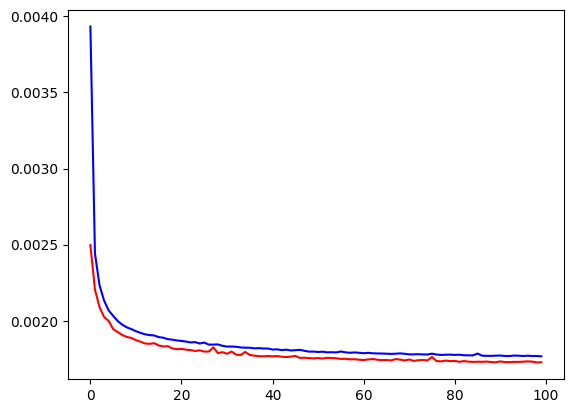

In [ ]:
import matplotlib.pyplot as plt
plt.plot(history.history['loss'], 'b-')
plt.plot(history.history['val_loss'], 'r-')
plt.show()

In [ ]:
encoder = tf.keras.Sequential([enc_in,enc_c1,enc_c2,enc_f,enc_d1,enc_d2])
encoder.summary()

decoder = tf.keras.Sequential([dec_d2,dec_d1,dec_r,dec_u1,dec_c1,dec_u2,dec_c2,dec_c3])
decoder.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │         4,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 15, 15, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 14400)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     3,686,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,710,594 (14.15 MB)

 Trainable params: 3,710,594 (14.15 MB)

 Non-trainable params: 0 (0.00 B)

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 256)            │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3825)           │       983,025 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 15, 15, 17)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 30, 30, 17)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 30, 30, 64)     │         9,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 60, 60, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 60, 60, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 60, 60, 17)     │         4,913 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,017,026 (3.88 MB)

 Trainable params: 1,017,026 (3.88 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
print(xx1_train.shape)

(8000, 60, 60, 17)


In [ ]:

embedding1k = encoder(xx1_train).numpy()
embedding1k.shape

embedding2k = encoder(xx2_train).numpy()
embedding2k.shape

embedding4k = encoder(xx4_train).numpy()
embedding4k.shape

embedding10k = encoder(xx10_train).numpy()
embedding10k.shape

embedding = np.concat((embedding1k, embedding2k, embedding4k, embedding10k), axis=0)
xmin = np.min(embedding[:,0]) - 0.5
xmax = np.max(embedding[:,0]) + 0.5
ymin = np.min(embedding[:,1]) - 0.5
ymax = np.max(embedding[:,1]) + 0.5


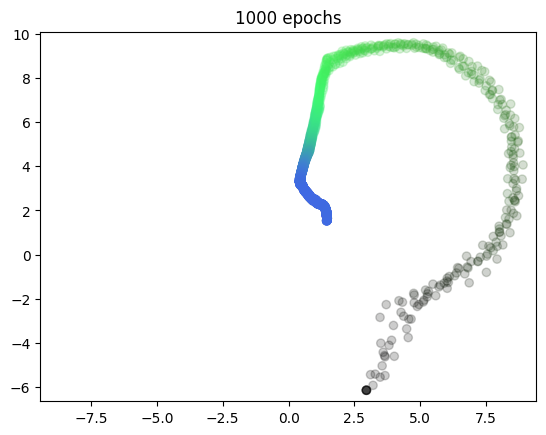

In [ ]:
#@title Plot latent space (1000 epochs) {vertical-output: true}
xx_rgb = xx1_train.reshape((SAMPLES,60,60,CHANNEL_N))[...,:3]
xx_rgb = np.mean(xx_rgb, axis=(1,2))

xx_rgb -= np.min(xx_rgb)
xx_rgb /= (np.max(xx_rgb))

colours  = xx_rgb


import matplotlib.pyplot as plt

plt.scatter(embedding1k[:,0],
            embedding1k[:,1],
            # c = list(range(len(embedding[:,0]))),
            c = colours,
            alpha = 0.2)
plt.title('1000 epochs')
ax = plt.gca()
ax.set_xlim([xmin, xmax])
ax.set_ylim([ymin, ymax])
plt.show()



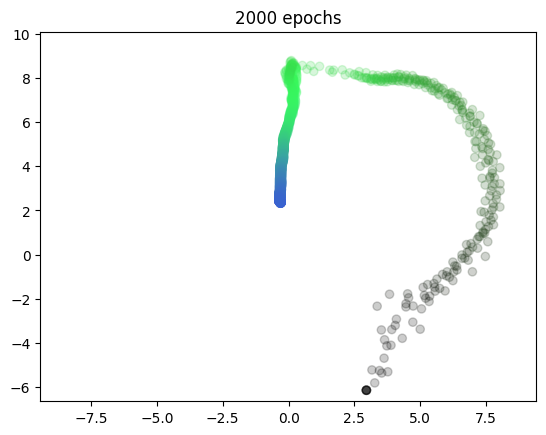

In [ ]:
#@title Plot latent space (2000 epochs) {vertical-output: true}
xx_rgb = xx2_train.reshape((SAMPLES,60,60,CHANNEL_N))[...,:3]
xx_rgb = np.mean(xx_rgb, axis=(1,2))

xx_rgb -= np.min(xx_rgb)
xx_rgb /= (np.max(xx_rgb))

colours  = xx_rgb


import matplotlib.pyplot as plt

plt.scatter(embedding2k[:,0],
            embedding2k[:,1],
            # c = list(range(len(embedding[:,0]))),
            c = colours,
            alpha = 0.2)
plt.title('2000 epochs')
ax = plt.gca()
ax.set_xlim([xmin, xmax])
ax.set_ylim([ymin, ymax])
plt.show()



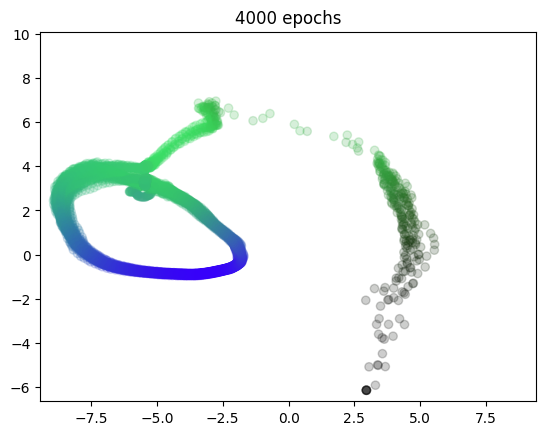

In [ ]:
#@title Plot latent space (4000 epochs) {vertical-output: true}
xx_rgb = xx4_train.reshape((SAMPLES,60,60,CHANNEL_N))[...,:3]
xx_rgb = np.mean(xx_rgb, axis=(1,2))

xx_rgb -= np.min(xx_rgb)
xx_rgb /= (np.max(xx_rgb))

colours  = xx_rgb

# embedding = np.concat((embedding1k, embedding2k, embedding4k), axis=0)
import matplotlib.pyplot as plt

plt.scatter(embedding4k[:,0],
            embedding4k[:,1],
            # c = list(range(len(embedding[:,0]))),
            c = colours,
            alpha = 0.2)
plt.title('4000 epochs')
ax = plt.gca()
ax.set_xlim([xmin, xmax])
ax.set_ylim([ymin, ymax])
plt.show()

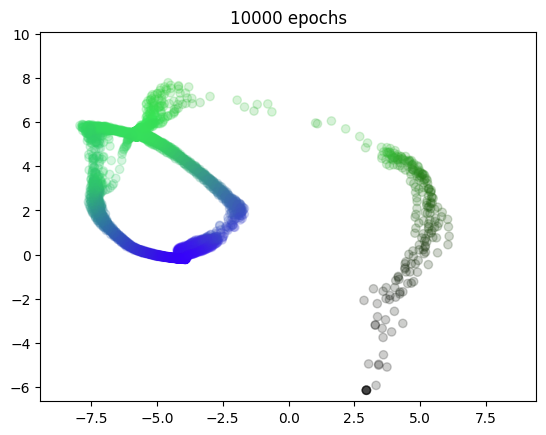

In [ ]:
#@title Plot latent space (10000 epochs) {vertical-output: true}
xx_rgb = xx10_train.reshape((SAMPLES,60,60,CHANNEL_N))[...,:3]
xx_rgb = np.mean(xx_rgb, axis=(1,2))

xx_rgb -= np.min(xx_rgb)
xx_rgb /= (np.max(xx_rgb))

colours  = xx_rgb

# embedding = np.concat((embedding1k, embedding2k, embedding4k), axis=0)
import matplotlib.pyplot as plt

plt.scatter(embedding10k[:,0],
            embedding10k[:,1],
            # c = list(range(len(embedding[:,0]))),
            c = colours,
            alpha = 0.2)
plt.title('10000 epochs')
ax = plt.gca()
ax.set_xlim([xmin, xmax])
ax.set_ylim([ymin, ymax])
plt.show()

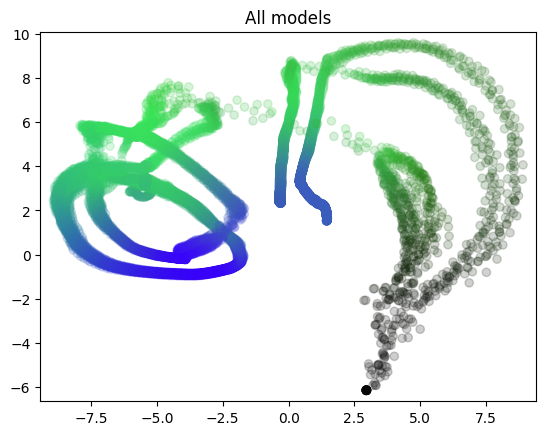

In [ ]:
#@title Plot latent space (all four models) {vertical-output: true}
xx_rgb = xx_train.reshape((SAMPLES * 4,60,60,CHANNEL_N))[...,:3]
xx_rgb = np.mean(xx_rgb, axis=(1,2))

xx_rgb -= np.min(xx_rgb)
xx_rgb /= (np.max(xx_rgb))

colours  = xx_rgb


import matplotlib.pyplot as plt

plt.scatter(embedding[:,0],
            embedding[:,1],
            # c = list(range(len(embedding[:,0]))),
            c = colours,
            alpha = 0.2)
plt.title('All models')
ax = plt.gca()
ax.set_xlim([xmin, xmax])
ax.set_ylim([ymin, ymax])
plt.show()

In [ ]:
#@title Set up colour maps

xx1_rgb = xx1_train.reshape((SAMPLES,60,60,CHANNEL_N))[...,:3]
xx1_rgb = np.mean(xx1_rgb, axis=(1,2))

xx1_rgb -= np.min(xx1_rgb)
xx1_rgb /= (np.max(xx1_rgb))

xx2_rgb = xx2_train.reshape((SAMPLES,60,60,CHANNEL_N))[...,:3]
xx2_rgb = np.mean(xx2_rgb, axis=(1,2))

xx2_rgb -= np.min(xx2_rgb)
xx2_rgb /= (np.max(xx2_rgb))

xx4_rgb = xx4_train.reshape((SAMPLES,60,60,CHANNEL_N))[...,:3]
xx4_rgb = np.mean(xx4_rgb, axis=(1,2))

xx4_rgb -= np.min(xx4_rgb)
xx4_rgb /= (np.max(xx4_rgb))

xx10_rgb = xx10_train.reshape((SAMPLES,60,60,CHANNEL_N))[...,:3]
xx10_rgb = np.mean(xx10_rgb, axis=(1,2))

xx10_rgb -= np.min(xx10_rgb)
xx10_rgb /= (np.max(xx10_rgb))

xx_rgb = xx_train.reshape((SAMPLES*4,60,60,CHANNEL_N))[...,:3]
xx_rgb = np.mean(xx_rgb, axis=(1,2))

xx_rgb -= np.min(xx_rgb)
xx_rgb /= (np.max(xx_rgb))



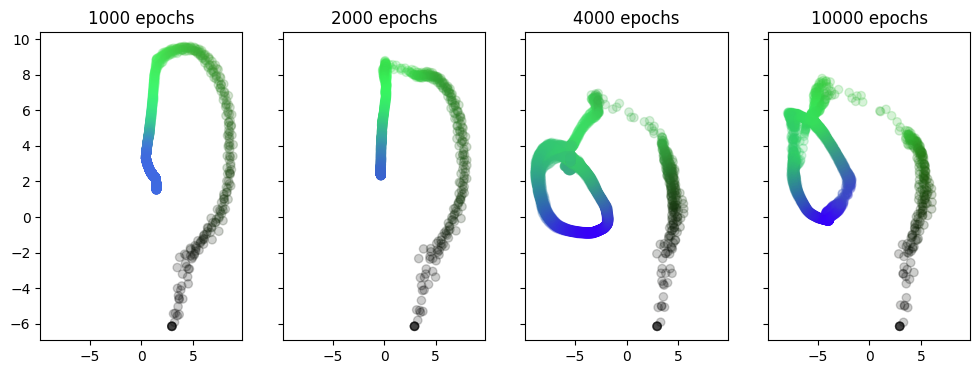

In [ ]:
fig = plt.figure(figsize=(12,4))
(ax1, ax2, ax4, ax10) = fig.subplots(1,4, sharex = True, sharey=True)


ax1.scatter(embedding1k[:,0],
            embedding1k[:,1],
            # c = list(range(len(embedding[:,0]))),
            c = xx1_rgb,
            alpha = 0.2)
ax1.set_title('1000 epochs')

ax2.scatter(embedding2k[:,0],
            embedding2k[:,1],
            c = xx2_rgb,
            alpha = 0.2)
ax2.set_title('2000 epochs')

ax4.scatter(embedding4k[:,0],
            embedding4k[:,1],
            c = xx4_rgb,
            alpha = 0.2)
ax4.set_title('4000 epochs')

ax10.scatter(embedding10k[:,0],
             embedding10k[:,1],
             c = xx10_rgb,
             alpha = 0.2)
ax10.set_title('10000 epochs')

plt.show()
fig.savefig(f'{root_dir}/4models_individual.png')

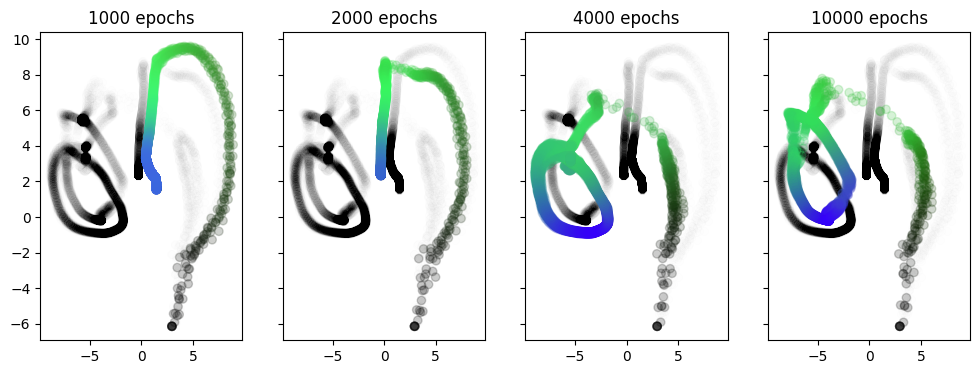

In [ ]:
fig = plt.figure(figsize=(12,4))
(ax1, ax2, ax4, ax10) = fig.subplots(1,4, sharex = True, sharey=True)


ax1.scatter(embedding[:,0],
            embedding[:,1],
            c = 'black',
            alpha = 0.005)


ax1.scatter(embedding1k[:,0],
            embedding1k[:,1],
            c = xx1_rgb,
            alpha = 0.2)
ax1.set_title('1000 epochs')

ax2.scatter(embedding[:,0],
            embedding[:,1],
            c = 'black',
            alpha = 0.005)

ax2.scatter(embedding2k[:,0],
            embedding2k[:,1],
            c = xx2_rgb,
            alpha = 0.2)
ax2.set_title('2000 epochs')

ax4.scatter(embedding[:,0],
            embedding[:,1],
            c = 'black',
            alpha = 0.005)

ax4.scatter(embedding4k[:,0],
            embedding4k[:,1],
            c = xx4_rgb,
            alpha = 0.2)
ax4.set_title('4000 epochs')

ax10.scatter(embedding[:,0],
            embedding[:,1],
            c = 'black',
            alpha = 0.005)

ax10.scatter(embedding10k[:,0],
             embedding10k[:,1],
             c = xx10_rgb,
             alpha = 0.2)
ax10.set_title('10000 epochs')

plt.show()
fig.savefig(f'{root_dir}/4models_overlay.png')